In [1]:
import numpy as np
from math import pi,sqrt
import matplotlib.pyplot as plt

# Importing standard Qiskit libraries
from qiskit import QuantumCircuit, transpile, Aer, IBMQ, execute, QuantumRegister
from qiskit.tools.jupyter import *
from qiskit.visualization import * # plot_bloch_multivector
from ibm_quantum_widgets import * # CircuitComposer
from qiskit.providers.aer import QasmSimulator
from qiskit.quantum_info import Statevector

# Loading your IBM Quantum account(s)
provider = IBMQ.load_account()

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [2]:
circuit = QuantumCircuit(1,1)
editor = CircuitComposer(circuit=circuit)
editor

CircuitComposer(circuit=<qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x7fc839b2f640>)

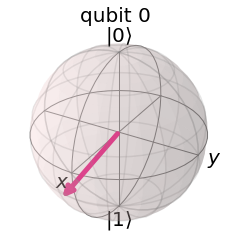

In [3]:
qc1 = editor.circuit
plot_bloch_multivector(qc1)

Statevector([0.40328148-0.10355339j, 0.65358207-0.63203735j],
            dims=(2,))
z=  (0.4+0.23j)


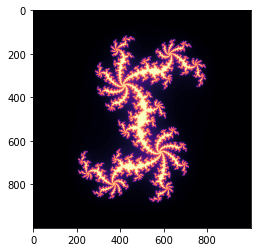

In [4]:
#qc1 = editor.circuit
backend = Aer.get_backend('statevector_simulator')
out = execute(qc1,backend).result().get_statevector()
print(out)
z0 = out.data[0]
z1 = out.data[1]
#print(z0,z1)

if z1.real != 0 or z1.imag != 0:
    z = z0/z1
    z = round(z.real, 2) + round(z.imag, 2) * 1j
else:
     z = 0 

print("z= ",z)

#z = -0.4+0.6j
heightsize = 1000 # 800
widthsize = heightsize # 1000


def julia_set(c=z, height=heightsize, width=widthsize, x=0, y=0, zoom=1, max_iterations=100):
    # To make navigation easier we calculate these values
    x_width = 1.5
    y_height = 1.5*height/width
    x_from = x - x_width/zoom
    x_to = x + x_width/zoom
    y_from = y - y_height/zoom
    y_to = y + y_height/zoom
    # Here the actual algorithm starts
    x = np.linspace(x_from, x_to, width).reshape((1, width))
    y = np.linspace(y_from, y_to, height).reshape((height, 1))
    z = x + 1j * y
    # Initialize z to all zero
    c = np.full(z.shape, c)
    # To keep track in which iteration the point diverged
    div_time = np.zeros(z.shape, dtype=int)
    # To keep track on which points did not converge so far
    m = np.full(c.shape, True, dtype=bool)
    for i in range(max_iterations):
        z[m] = z[m]**2 + c[m] 
        m[np.abs(z) > 2] = False
        div_time[m] = i
    return div_time

plt.imshow(julia_set(), cmap='magma') # viridis', 'plasma', 'inferno', 'magma', 'cividis'
plt.show()

#plt.savefig('plots/1qubit_simulator_H_U_pi4_-pi3_pi8.png')

# Running on a real quantum computer
### Identify least busy system, perform measurements and run on backend

In [5]:
# Find the least busy system that has at least 1 qubit
from qiskit.providers.ibmq import least_busy

ibmq_backend = least_busy(provider.backends(filters=lambda x: x.configuration().n_qubits >= 1 and 
                                   not x.configuration().simulator and x.status().operational==True))

print(ibmq_backend)

ibmq_quito


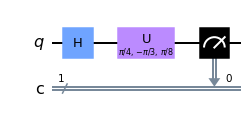

In [6]:
qc1.measure(0, 0)
qc1.draw()

In [7]:
shotno=1024
job_ibmq = execute(qc1, ibmq_backend, shots=shotno)
result = job_ibmq.result()

## Perform calculations and plot result

Observed probabilities of measuring the computational basis states 0.296 0.704
Statevector:  Statevector([0.40328148-0.10355339j, 0.65358207-0.63203735j],
            dims=(2,))
Statevector probilities of measuring the basis states:  [0.17335926 0.82664074]
(0.4+0.23j) (0.5634475619248455+0.320587738724221j)


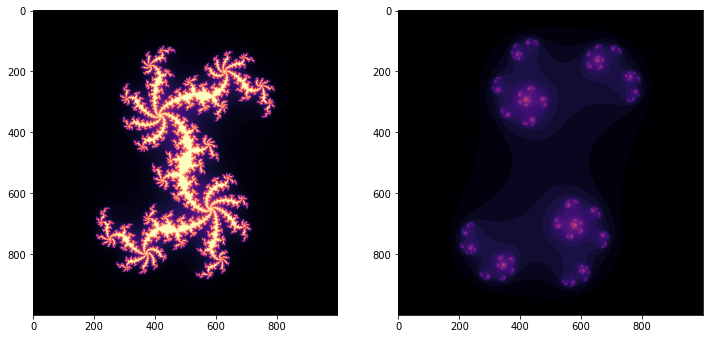

In [8]:
#job_ibmq = execute(qc1, ibmq_backend, shots=1024)
#result = job_ibmq.result()

counts = result.get_counts()

prob0qc = counts['0']/shotno
prob1qc = counts['1']/shotno
print("Observed probabilities of measuring the computational basis states", round(prob0qc,3), round(prob1qc,3))

print("Statevector: ", out)
print("Statevector probilities of measuring the basis states: ", out.probabilities())
prob0statevec = out.probabilities()[0]
prob1statevec = out.probabilities()[1]

# one simple approach # amplitude^2 = probability
z0qc = z0*sqrt(prob0qc/prob0statevec)
z1qc = z1*sqrt(prob1qc/prob1statevec)
zqc = z0qc/z1qc
print(z,zqc)

f, axarr = plt.subplots(1,2,figsize=(12, 12))
axarr[0].imshow(julia_set(c=z), cmap='magma')
axarr[1].imshow(julia_set(c=zqc), cmap='magma')

In [ ]:
plt.imshow(julia_set(c=zqc), cmap='magma')
#plt.savefig('plots/1qubit_realhw1_H_Upi4_-pi3_pi8.png')

In [ ]:
f, axarr = plt.subplots(1,2,figsize=(12, 12))
axarr[0].imshow(julia_set(c=z), cmap='magma')
axarr[1].imshow(julia_set(c=zqc), cmap='magma')
#plt.savefig('plots/2qubit_realhw1_both_bell_state1_U_pi4_-pi3_pi8.png')